### Import the necessary libraries

In [90]:
import os
import torch
import kagglehub
from torch import nn
import seaborn as sns
from PIL import ImageFile
from tqdm.auto import tqdm
from matplotlib import pyplot as plt
from torch.utils.data import DataLoader
from torchvision import transforms, models
from torchvision.datasets import ImageFolder
from sklearn.metrics import classification_report
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.metrics import confusion_matrix, roc_curve, auc

### Download latest version of the dataset from Kaggle

In [91]:
path = kagglehub.dataset_download("abdelghaniaaba/wildfire-prediction-dataset")
print("Path to dataset files:", path)

Path to dataset files: C:\Users\keert\.cache\kagglehub\datasets\abdelghaniaaba\wildfire-prediction-dataset\versions\1


### Load the dataset using ImageFolder and apply transformations

In [92]:
ImageFile.LOAD_TRUNCATED_IMAGES = True

train_dataset = ImageFolder(os.path.join(path, "train"), transform=transforms.ToTensor())
test_dataset = ImageFolder(os.path.join(path, "test"), transform=transforms.ToTensor())
valid_dataset = ImageFolder(os.path.join(path, "valid"), transform=transforms.ToTensor())

### Inspecting the data

Number of training samples: 30250
Number of test samples: 6300
Number of validation samples: 6300
Number of classes: 2
Class names: ['nowildfire', 'wildfire']
Class to index mapping: {'nowildfire': 0, 'wildfire': 1}
Image shape: torch.Size([3, 350, 350])


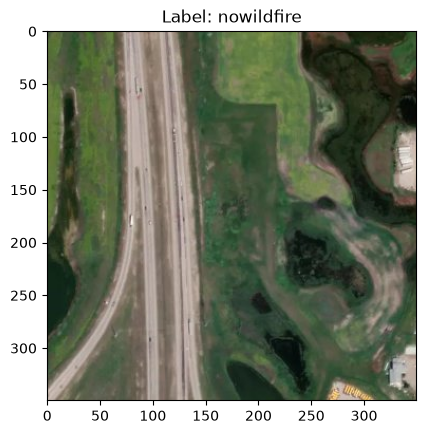

In [93]:
# Get attributes of the datasets
print("Number of training samples:", len(train_dataset))
print("Number of test samples:", len(test_dataset))
print("Number of validation samples:", len(valid_dataset))
print("Number of classes:", len(train_dataset.classes))
print("Class names:", train_dataset.classes)
print("Class to index mapping:", train_dataset.class_to_idx)
print("Image shape:", train_dataset[0][0].shape)

img, label = train_dataset[0]
plt.imshow(img.permute(1, 2, 0))
plt.title(f"Label: {train_dataset.classes[label]}")
plt.show()

### Create the dataloaders

In [94]:
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)
valid_dataloader = DataLoader(valid_dataset, batch_size=32, shuffle=False)

### Create the model

In [95]:
# Check if GPU is available and set the device accordingly
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load the pre-trained ResNet18 model
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze the convolutional base
for param in model.parameters():
    param.requires_grad = False
    
# Replace the classification head for binary output
num_ftrs = model.fc.in_features

# Binary classification (2 classes)
model.fc = nn.Linear(num_ftrs, 2)

model = model.to(device)

print("Model architecture:")
print(model)

Device: cuda
Model architecture:
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  

### Define the loss function and optimizer

In [96]:
# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()

# Pass the parameters that have requires_grad = True, apply weight decay for L2 regularization
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4, weight_decay=1e-5)

# Reduces LR by half (factor=0.5) if validation loss doesn't improve for 2 epochs
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

### Training functions

In [97]:
def plot_learning_curves(history):
    """Plots loss and accuracy side-by-side for training and validation."""
    num_epochs = len(history["train_loss"])
    epochs = range(1, num_epochs + 1)
    
    plt.figure(figsize=(14, 5))

    # Loss plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], label="Train Loss", marker="o")
    plt.plot(epochs, history["valid_loss"], label="Validation Loss", marker="o")
    plt.title("Training & Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.legend()

    # Accuracy plot
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["train_acc"], label="Train Accuracy", marker="o")
    plt.plot(epochs, history["valid_acc"], label="Validation Accuracy", marker="o")
    plt.title("Training & Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()

In [98]:
def train_model(
    model, 
    criterion, 
    optimizer, 
    scheduler, 
    train_loader, 
    valid_loader, 
    num_epochs=10, 
    patience=3  # Stop if no improvement for 3 consecutive epochs
):
    history = {
        "train_loss": [], "train_acc": [],
        "valid_loss": [], "valid_acc": []
    }
    
    best_valid_loss = float('inf')
    epochs_no_improve = 0  # Counter for early stopping

    for epoch in range(num_epochs):
        # ================= TRAIN PHASE =================
        model.train()
        running_loss, correct_train, total_train = 0.0, 0, 0
        
        train_progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{num_epochs} [Train]")
        for inputs, labels in train_progress:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            predicted = torch.argmax(outputs, dim=1)
            correct_train += (predicted == labels).sum().item()
            total_train += labels.size(0)
            
            train_progress.set_postfix(
                loss=f"{running_loss / total_train:.4f}", 
                acc=f"{correct_train / total_train:.4f}"
            )

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = correct_train / total_train
        history["train_loss"].append(epoch_train_loss)
        history["train_acc"].append(epoch_train_acc)

        # ================= VALIDATION PHASE =================
        model.eval()
        valid_loss, correct_valid, total_valid = 0.0, 0, 0
        
        with torch.no_grad():
            valid_progress = tqdm(valid_loader, desc=f"Epoch {epoch + 1}/{num_epochs} [Valid]")
            for inputs, labels in valid_progress:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                
                valid_loss += loss.item() * inputs.size(0)
                predicted = torch.argmax(outputs, dim=1)
                total_valid += labels.size(0)
                correct_valid += (predicted == labels).sum().item()
                
                valid_progress.set_postfix(
                    loss=f"{valid_loss / total_valid:.4f}", 
                    acc=f"{correct_valid / total_valid:.4f}"
                )

        epoch_valid_loss = valid_loss / len(valid_loader.dataset)
        epoch_valid_acc = correct_valid / total_valid if total_valid > 0 else 0
        history["valid_loss"].append(epoch_valid_loss)
        history["valid_acc"].append(epoch_valid_acc)

        current_lr = optimizer.param_groups[0]['lr']
        print(f"\nEpoch {epoch+1}/{num_epochs} | LR: {current_lr:.6f}")
        print(f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f}")
        print(f"Valid Loss: {epoch_valid_loss:.4f} | Valid Acc: {epoch_valid_acc:.4f}")

        # Update Learning Rate Scheduler
        scheduler.step(epoch_valid_loss)

        # Checkpoint and Early Stopping Logic
        if epoch_valid_loss < best_valid_loss:
            best_valid_loss = epoch_valid_loss
            epochs_no_improve = 0  # Reset counter on improvement
            
            torch.save(model.state_dict(), "satellite_image_classification_model.pth")
            print(f"--> Saved best model checkpoint (Validation Loss improved to {best_valid_loss:.4f})")
        else:
            epochs_no_improve += 1
            print(f"--> Validation loss did not improve. Early stopping counter: {epochs_no_improve}/{patience}")

        print("-" * 60)

        # Trigger Early Stopping break
        if epochs_no_improve >= patience:
            print(f"\nEarly stopping triggered! Training stopped at epoch {epoch + 1}.")
            break

    return history

### Testing functions

In [99]:
def plot_test_results(y_true, y_pred, y_probs, class_names=None):
    """Plots Confusion Matrix and ROC Curve for test set evaluation."""
    if class_names is None:
        class_names = ["Class 0", "Class 1"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # 1. Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title("Test Confusion Matrix")
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")

    # 2. ROC Curve
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    roc_auc = auc(fpr, tpr)

    axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.3f})")
    axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_ylim([0.0, 1.05])
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].set_title("Test Receiver Operating Characteristic (ROC)")
    axes[1].legend(loc="lower right")
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

In [100]:
def test_model(model, test_loader, class_names=None):
    """Evaluates test accuracy and plots Confusion Matrix & ROC Curve."""
    model.eval()
    correct = 0
    total = 0
    
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for inputs, labels in tqdm(test_loader, desc="Testing"):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            
            # Apply Softmax to obtain probabilities for class 1
            probs = torch.softmax(outputs, dim=1)[:, 1]
            predicted = torch.argmax(outputs, dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    test_acc = correct / total

    print(f"\nFinal Test Accuracy: {test_acc:.4f}\n")
    print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

    # Plot Confusion Matrix & ROC Curve
    plot_test_results(all_labels, all_preds, all_probs, class_names)

### Run the model

In [101]:
# Train the model
num_epochs = 25
train_results = train_model(model, criterion, optimizer, scheduler, train_dataloader, valid_dataloader, num_epochs=num_epochs)

Epoch 1/25 [Valid]: 100%|██████████| 197/197 [00:55<00:00,  3.54it/s, acc=0.9402, loss=0.1728]



Epoch 1/25 | LR: 0.000100
Train Loss: 0.3112 | Train Acc: 0.8810
Valid Loss: 0.1728 | Valid Acc: 0.9402
--> Saved best model checkpoint (Validation Loss improved to 0.1728)
------------------------------------------------------------


Epoch 2/25 [Valid]: 100%|██████████| 197/197 [00:48<00:00,  4.03it/s, acc=0.9452, loss=0.1449]



Epoch 2/25 | LR: 0.000100
Train Loss: 0.1818 | Train Acc: 0.9342
Valid Loss: 0.1449 | Valid Acc: 0.9452
--> Saved best model checkpoint (Validation Loss improved to 0.1449)
------------------------------------------------------------


Epoch 3/25 [Valid]: 100%|██████████| 197/197 [00:44<00:00,  4.40it/s, acc=0.9529, loss=0.1354]


...


Epoch 15/25 | LR: 0.000100
Train Loss: 0.1206 | Train Acc: 0.9560
Valid Loss: 0.0974 | Valid Acc: 0.9678
--> Validation loss did not improve. Early stopping counter: 1/3
------------------------------------------------------------


Epoch 16/25 [Valid]: 100%|██████████| 197/197 [00:25<00:00,  7.78it/s, acc=0.9663, loss=0.0997]



Epoch 16/25 | LR: 0.000100
Train Loss: 0.1159 | Train Acc: 0.9576
Valid Loss: 0.0997 | Valid Acc: 0.9663
--> Validation loss did not improve. Early stopping counter: 2/3
------------------------------------------------------------


Epoch 17/25 [Valid]: 100%|██████████| 197/197 [00:25<00:00,  7.73it/s, acc=0.9643, loss=0.1027]


Epoch 17/25 | LR: 0.000100
Train Loss: 0.1169 | Train Acc: 0.9572
Valid Loss: 0.1027 | Valid Acc: 0.9643
--> Validation loss did not improve. Early stopping counter: 3/3
------------------------------------------------------------

Early stopping triggered! Training stopped at epoch 17.


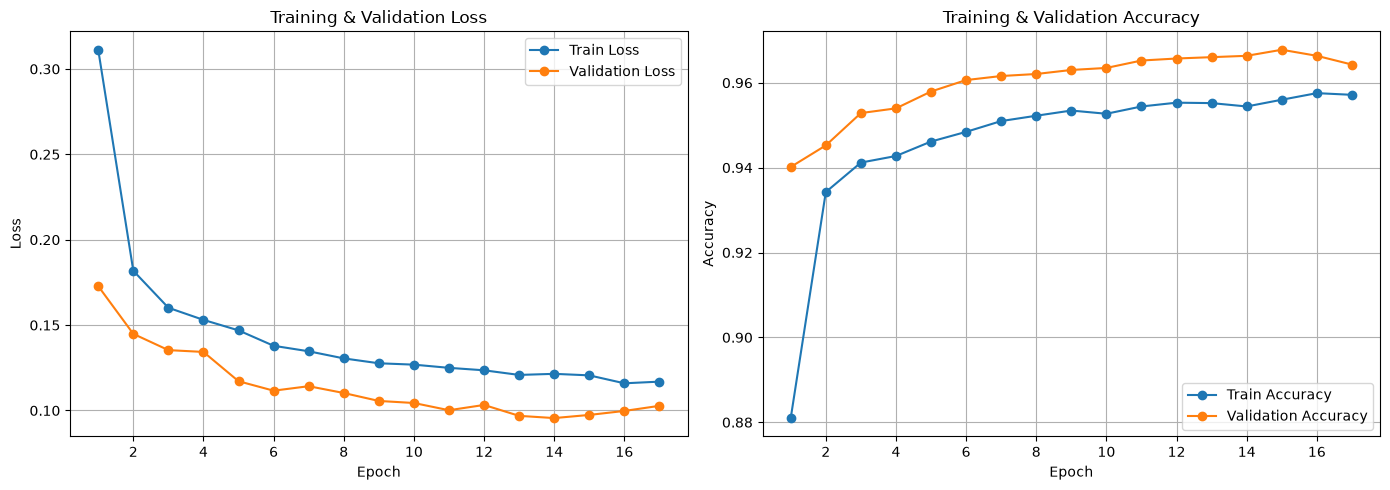

In [102]:
# Plot learning curves for training and validation
plot_learning_curves(train_results)

### Test the model

Testing: 100%|██████████| 197/197 [00:28<00:00,  6.99it/s]



Final Test Accuracy: 0.9713

              precision    recall  f1-score   support

  nowildfire     0.9530    0.9844    0.9684      2820
    wildfire     0.9870    0.9606    0.9736      3480

    accuracy                         0.9713      6300
   macro avg     0.9700    0.9725    0.9710      6300
weighted avg     0.9718    0.9713    0.9713      6300



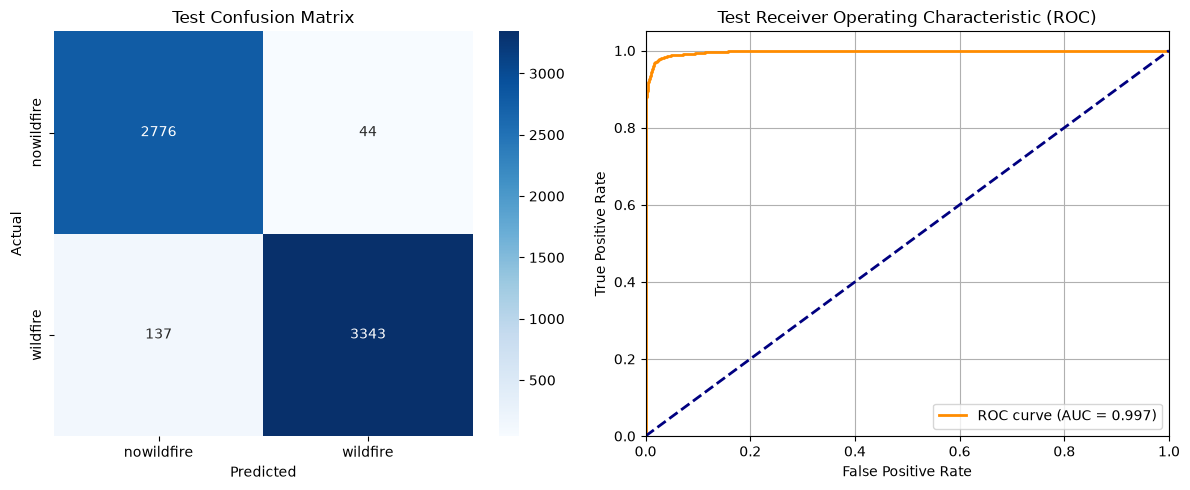

In [103]:
# Test the model
test_model(model, test_dataloader, class_names=train_dataset.classes)